# 09 · How Much Does a Careless Split Inflate the Scores?

**The question:** Many papers report 95-99% on UNSW-NB15. Part of that may come from **leakage**: identical flows ending up in both the
training and the test part. How much does the way we split the data change the score of the *same* model?

| | |
|---|---|
| **Input** | The official training file (175,341 rows), the 42 original predictors |
| **What we do** | Train the same LightGBM with three common ways of splitting the data, 5 times each (5-fold cross-validation), and compare |
| **Output** | The measured inflation per split method and per class, and the mechanism behind it |

This is research question **RQ1** of the project (see `docs/ROADMAP.md`).

**Protocol note:** only the training file is used. The official test file stays untouched until the single final evaluation (Notebook 20).

## 1. The three ways to split

| Split method | How it works | Common in papers? |
|---|---|---|
| **A. Random split** | Rows are shuffled and divided at random (keeping class shares) | Very common |
| **B. Drop duplicates, then random split** | Remove rows that are exact copies (same 42 measurements **and** same label), then split at random | The usual "fix" |
| **C. Grouped split** (ours) | Rows with the same 42 measurements always go to the same side, whatever their label | Rare |

Why can A and B leak? Remember Notebook 02: 74,301 training rows are exact repeats of another row's measurements.

- With **A**, a copy can be in the training part and its twin in the test part. The model only needs to recognise it.
- With **B**, exact copies are gone, but rows with the **same measurements and a different label** remain. One version can be in training and the
  other in the test part.
- With **C**, no test row ever has a measurement twin in training.

A tiny example makes it concrete:

In [1]:
import sys
import time
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lightgbm import LGBMClassifier
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder

from src.notebook_helpers import (TRAIN_CSV, RAW_SHA256, TARGETS, CATEGORICAL, CLASSES, DATA,
                                  sha256, save_table, save_figure, save_json, setup_style)
setup_style()
warnings.filterwarnings('ignore', message='X does not have valid feature names')

toy = pd.DataFrame({'bytes': [100, 100, 100, 200, 300], 'label': ['DoS', 'DoS', 'Exploits', 'Normal', 'Normal']})
toy['pattern'] = toy.groupby('bytes').ngroup()
toy['after dropping exact copies?'] = ~toy.duplicated(['bytes', 'label'])
display(toy)

,bytes,label,pattern,after dropping exact copies?
0,100,DoS,0,True
1,100,DoS,0,False
2,100,Exploits,0,True
3,200,Normal,1,True
4,300,Normal,2,True


Rows 0 and 1 are exact copies: method B keeps only one. Row 2 has the **same measurement** (100 bytes) but a different label, so B keeps it.
Methods A and B can put row 0 in training and row 2 in the test part. Method C keeps all three rows of pattern 0 together.

## 2. Load the data

In [2]:
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
raw = pd.read_csv(TRAIN_CSV, low_memory=False)
predictors = [c for c in raw.columns if c not in TARGETS]
numeric = [c for c in predictors if c not in CATEGORICAL]
raw['pattern'] = raw.groupby(predictors, sort=False).ngroup()
y_all = pd.Categorical(raw.attack_cat, categories=CLASSES).codes.astype(np.int64)

exact_copy = raw.duplicated(predictors + ['attack_cat'])
deduplicated = raw[~exact_copy].reset_index(drop=True)
print(f'rows: {len(raw):,} | distinct patterns: {raw.pattern.nunique():,}')
print(f'method B removes {exact_copy.sum():,} exact copies -> {len(deduplicated):,} rows remain')

rows: 175,341 | distinct patterns: 101,040
method B removes 67,601 exact copies -> 107,740 rows remain


## 3. The same model and rules for every method

- **Model:** LightGBM with the frozen settings from Notebook 06 (120 trees, 31 leaves, `reg_lambda=1.0`). It gives identical results for any seed,
  so every difference below comes from the split alone.
- **Inputs:** the 42 original predictors; numbers unchanged, text columns one-hot encoded. The encoder is fitted on each training part only.
- **5-fold cross-validation:** the data is cut into 5 parts; each part serves once as the test part while the other 4 train the model.
- **Main score:** macro F1 over the 10 classes. Accuracy is also shown, because it is what most papers report.

In [3]:
def make_model():
    return LGBMClassifier(objective='multiclass', n_estimators=120, learning_rate=0.1, num_leaves=31, reg_lambda=1.0,
                          min_child_samples=20, random_state=42, n_jobs=8, deterministic=True, force_col_wise=True, verbosity=-1)


def run_fold(frame, train_rows, test_rows):
    """Fit the encoder and the model on the training part, predict the test part."""
    encoder = ColumnTransformer([('num', 'passthrough', numeric),
                                 ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)], sparse_threshold=1.0)
    x_train = sparse.csr_matrix(encoder.fit_transform(frame.iloc[train_rows][predictors]), dtype=np.float64)
    x_test = sparse.csr_matrix(encoder.transform(frame.iloc[test_rows][predictors]), dtype=np.float64)
    y = pd.Categorical(frame.attack_cat, categories=CLASSES).codes.astype(np.int64)
    model = make_model().fit(x_train, y[train_rows])
    return model.predict(x_test)


METHODS = {
    'A random split': dict(frame=raw, splitter=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), grouped=False),
    'B drop copies, then random': dict(frame=deduplicated, splitter=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), grouped=False),
    'C grouped split (ours)': dict(frame=raw, splitter=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), grouped=True),
}

## 4. Run the 15 experiments (3 methods × 5 folds)

For every test row we also record whether its **exact measurement pattern was present in the training part** of that fold.
This tells us *why* a score is inflated, not only *that* it is.

In [4]:
fold_rows, row_records = [], []
for method, spec in METHODS.items():
    frame = spec['frame']
    y = pd.Categorical(frame.attack_cat, categories=CLASSES).codes.astype(np.int64)
    groups = frame.pattern.to_numpy()
    split = spec['splitter'].split(np.zeros(len(frame)), y, groups) if spec['grouped'] else spec['splitter'].split(np.zeros(len(frame)), y)
    for fold, (train_rows, test_rows) in enumerate(split, start=1):
        start = time.time()
        pred = run_fold(frame, train_rows, test_rows)
        seen = np.isin(groups[test_rows], groups[train_rows])
        fold_rows.append({'method': method, 'fold': fold, 'test rows': len(test_rows),
                          'macro F1': f1_score(y[test_rows], pred, average='macro', labels=range(10), zero_division=0),
                          'accuracy': accuracy_score(y[test_rows], pred),
                          'binary accuracy (Normal vs Attack)': np.mean((y[test_rows] == CLASSES.index('Normal')) == (pred == CLASSES.index('Normal'))),
                          '% test rows whose pattern is in training': seen.mean() * 100})
        row_records.append(pd.DataFrame({'method': method, 'fold': fold, 'true': y[test_rows], 'pred': pred, 'seen': seen}))
        print(f'{method:28s} fold {fold}: macro F1 {fold_rows[-1]["macro F1"]:.4f} | seen patterns {seen.mean() * 100:5.1f}% | {time.time() - start:.0f} s')

folds = pd.DataFrame(fold_rows)
rows = pd.concat(row_records, ignore_index=True)
save_table(folds, '09_folds')

A random split               fold 1: macro F1 0.6182 | seen patterns  46.8% | 7 s


A random split               fold 2: macro F1 0.6222 | seen patterns  46.9% | 7 s


A random split               fold 3: macro F1 0.6157 | seen patterns  46.8% | 7 s


A random split               fold 4: macro F1 0.6135 | seen patterns  46.7% | 7 s


A random split               fold 5: macro F1 0.6225 | seen patterns  47.1% | 7 s


B drop copies, then random   fold 1: macro F1 0.6079 | seen patterns   7.7% | 5 s


... (6 outputs left out)

C grouped split (ours)       fold 3: macro F1 0.6194 | seen patterns   0.0% | 7 s


C grouped split (ours)       fold 4: macro F1 0.6073 | seen patterns   0.0% | 7 s


C grouped split (ours)       fold 5: macro F1 0.6099 | seen patterns   0.0% | 7 s


WindowsPath('D:/projects/Botnet attack detection/results/tables/v3/09_folds.csv')

## 5. Results

,macro F1 mean,macro F1 std,accuracy mean,binary accuracy mean,% test rows seen in training,macro F1 inflation vs C,accuracy inflation vs C
method,,,,,,,
A random split,0.6184,0.0040,0.8371,0.9588,46.8476,0.0038,0.0027
"B drop copies, then random",0.6015,0.0084,0.8224,0.9357,7.6610,-0.0131,-0.0120
C grouped split (ours),0.6146,0.0056,0.8344,0.9557,0.0000,0.0000,0.0000


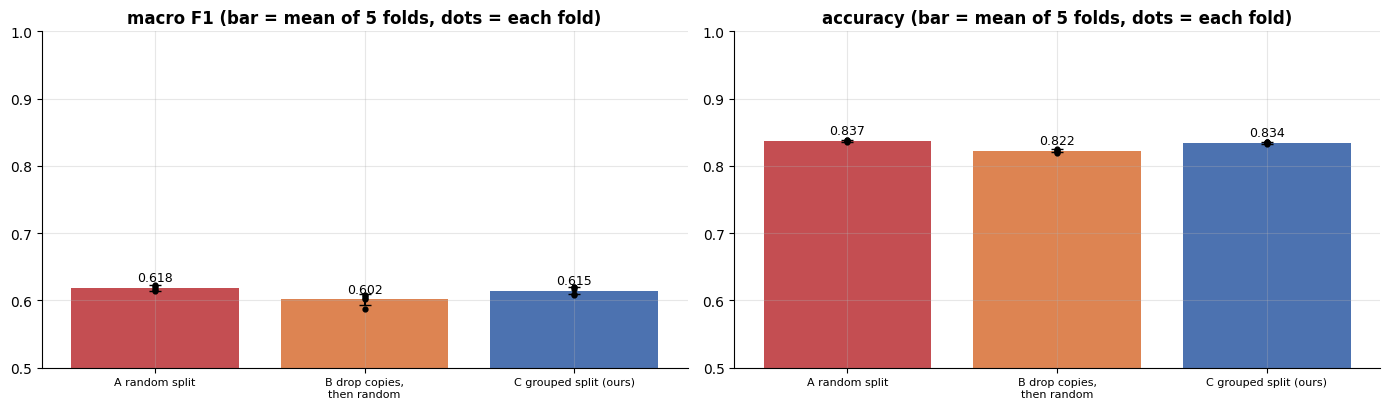

In [5]:
summary = folds.groupby('method', sort=False).agg(
    **{'macro F1 mean': ('macro F1', 'mean'), 'macro F1 std': ('macro F1', 'std'),
       'accuracy mean': ('accuracy', 'mean'), 'binary accuracy mean': ('binary accuracy (Normal vs Attack)', 'mean'),
       '% test rows seen in training': ('% test rows whose pattern is in training', 'mean')})
reference = summary.loc['C grouped split (ours)']
summary['macro F1 inflation vs C'] = summary['macro F1 mean'] - reference['macro F1 mean']
summary['accuracy inflation vs C'] = summary['accuracy mean'] - reference['accuracy mean']
save_table(summary, '09_summary', index=True)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
colors = ['#C44E52', '#DD8452', '#4C72B0']
for ax, metric in zip(axes, ['macro F1', 'accuracy']):
    for i, method in enumerate(METHODS):
        values = folds.loc[folds.method == method, metric]
        ax.bar(i, values.mean(), color=colors[i], yerr=values.std(), capsize=4)
        ax.scatter([i] * len(values), values, color='black', s=12, zorder=3)
        ax.text(i, values.mean() + 0.01, f'{values.mean():.3f}', ha='center', fontsize=9)
    ax.set_xticks(range(3), [m.replace(', then', ',\nthen') for m in METHODS], fontsize=8)
    ax.set(title=f'{metric} (bar = mean of 5 folds, dots = each fold)', ylim=(0.5, 1.0))
plt.tight_layout(); save_figure(fig, '09_split_methods'); plt.show()

**What we see:**

- **The three methods give almost the same score.** Random split 0.618, grouped split 0.615: a difference of only **+0.004**, smaller than the
  variation between folds.
- This is surprising: with the random split, **47%** of the test rows have an exact measurement twin in training, yet the score is barely higher.
- **Dropping copies first (B) gives the *lowest* score (0.602)**, about 0.013 below our grouped split. The usual "fix" does not remove a bias here; it adds one.
- Accuracy tells the same story (0.837 / 0.822 / 0.834), and Normal-vs-Attack accuracy is about 0.94-0.96 for all three.

## 6. The mechanism: seen versus new patterns

Inside each method we split the test rows into two groups: rows whose exact measurements **were in the training part** ("seen") and rows that
**were not** ("new"). If leakage drives the inflation, the model should be much better on seen rows.

In [6]:
mechanism = []
for (method, seen), part in rows.groupby(['method', 'seen'], sort=False):
    mechanism.append({'method': method, 'test rows': 'seen in training' if seen else 'new',
                      'rows': len(part), 'accuracy': accuracy_score(part.true, part.pred),
                      'macro F1': f1_score(part.true, part.pred, average='macro', labels=range(10), zero_division=0)})
mechanism = pd.DataFrame(mechanism)
save_table(mechanism, '09_seen_vs_new')
display(mechanism)

,method,test rows,rows,accuracy,macro F1
0,A random split,new,93198,0.8782,0.6923
1,A random split,seen in training,82143,0.7906,0.5583
2,"B drop copies, then random",new,99486,0.8822,0.7211
3,"B drop copies, then random",seen in training,8254,0.1019,0.1259
4,C grouped split (ours),new,175341,0.8344,0.6147


**What we see:**

- **Random split (A):** rows the model has "seen" are predicted **worse** (accuracy 0.79) than new rows (0.88).
  Recognising a twin does not help, because repeated patterns are exactly where the conflicting labels are (Notebook 02): the model can give
  only one answer to identical measurements, and part of the copies carry another label.
- **Drop copies first (B):** after exact copies are removed, every remaining twin in training has, by construction, a **different label** from the test row.
  So these 7.7% "seen" rows are guaranteed contradictions, and the model gets only **10%** of them right. That is why method B scores lowest.
- **Grouped split (C):** no test row has a twin in training, so the score measures performance on genuinely new measurement patterns.

## 7. Which classes are inflated most?

Per-class F1, pooled over the 5 folds, for the random split (A) and our grouped split (C).

,A random split,"B drop copies, then random",C grouped split (ours),inflation A - C,rows per pattern
Analysis,0.2665,0.1517,0.2258,0.0406,1.2547
DoS,0.1341,0.2848,0.1173,0.0169,3.2223
Fuzzers,0.7608,0.7261,0.7503,0.0105,1.1259
Normal,0.9348,0.9325,0.9299,0.0049,1.0792
Reconnaissance,0.8305,0.7747,0.8281,0.0024,1.3947
Shellcode,0.7050,0.7053,0.7029,0.0021,1.0385
Generic,0.9901,0.9040,0.9903,-0.0002,9.5671
Exploits,0.7507,0.8339,0.7516,-0.0009,1.6828
Backdoor,0.2348,0.1711,0.2404,-0.0056,1.1375
Worms,0.5809,0.5333,0.6102,-0.0293,1.0236


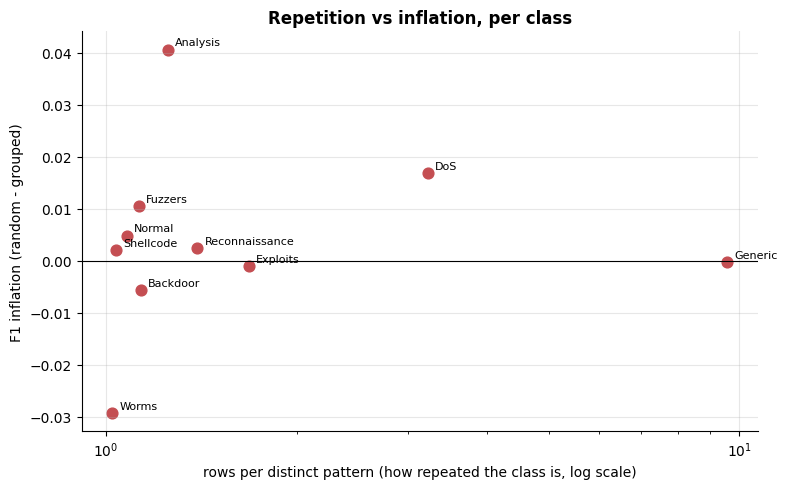

Spearman correlation between repetition and inflation: 0.224


In [7]:
def per_class(method):
    part = rows[rows.method == method]
    return pd.Series(f1_score(part.true, part.pred, average=None, labels=range(10), zero_division=0), index=CLASSES)


by_class = pd.DataFrame({m: per_class(m) for m in METHODS})
by_class['inflation A - C'] = by_class['A random split'] - by_class['C grouped split (ours)']
repetition = raw.groupby('attack_cat').agg(rows=('pattern', 'size'), patterns=('pattern', 'nunique'))
by_class['rows per pattern'] = (repetition.rows / repetition.patterns).reindex(CLASSES)
by_class = by_class.sort_values('inflation A - C', ascending=False)
save_table(by_class, '09_inflation_by_class', index=True)
display(by_class)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(by_class['rows per pattern'], by_class['inflation A - C'], s=60, color='#C44E52')
for name, r in by_class.iterrows():
    ax.annotate(name, (r['rows per pattern'], r['inflation A - C']), xytext=(5, 3), textcoords='offset points', fontsize=8)
ax.axhline(0, color='black', lw=0.8)
ax.set(xscale='log', xlabel='rows per distinct pattern (how repeated the class is, log scale)',
       ylabel='F1 inflation (random - grouped)', title='Repetition vs inflation, per class')
plt.tight_layout(); save_figure(fig, '09_inflation_vs_repetition'); plt.show()
print('Spearman correlation between repetition and inflation:',
      round(by_class[['rows per pattern', 'inflation A - C']].corr(method='spearman').iloc[0, 1], 3))

**What we see:**

- Per-class differences between the random and the grouped split are small: the largest gains are Analysis (+0.04) and DoS (+0.02), and
  Worms even scores lower with the random split (-0.03). With only about 26 Worms rows per test fold, one or two rows make that difference.
- **There is no clear link between how repeated a class is and how much it is inflated** (Spearman correlation 0.22). Generic, the most repeated
  class (about 9.6 rows per pattern), is not inflated at all.

## 8. Is the difference real?

Each method was run on 5 folds. We compare the 5 fold scores of A and B against C with a simple check: is **every** fold of A (or B)
above **every** fold of C? We also report the difference in means with its spread.

In [8]:
check = []
c_scores = folds.loc[folds.method == 'C grouped split (ours)', 'macro F1']
for method in ['A random split', 'B drop copies, then random']:
    scores = folds.loc[folds.method == method, 'macro F1']
    check.append({'comparison': f'{method} vs C', 'mean difference': scores.mean() - c_scores.mean(),
                  'lowest fold of method': scores.min(), 'highest fold of C': c_scores.max(),
                  'every fold higher than every C fold': bool(scores.min() > c_scores.max())})
check = pd.DataFrame(check)
save_table(check, '09_significance')
display(check)

,comparison,mean difference,lowest fold of method,highest fold of C,every fold higher than every C fold
0,A random split vs C,0.0038,0.6135,0.6196,False
1,"B drop copies, then random vs C",-0.0131,0.5870,0.6196,False


**What we see:** neither difference is consistent: some folds of the random split score lower than some folds of the grouped split, and the same is true
for method B. So the random split's small advantage could be chance, while method B is lower on average but also not lower in every fold.

## 9. Save

In [9]:
save_json({'question': 'RQ1: score inflation from the split method on UNSW-NB15 (official training file only)',
           'model': 'LightGBM, frozen Notebook 06 settings', 'features': 'original 42 predictors',
           'methods': list(METHODS), 'folds': 5, 'official_test_file_used': False},
          DATA / '09_settings.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved fold scores, summary, seen-vs-new and per-class tables. The official test file was not used.')

Saved fold scores, summary, seen-vs-new and per-class tables. The official test file was not used.


## Summary

### What we learned

| Question | Answer |
|---|---|
| Does a random split inflate the score on UNSW-NB15? | **Hardly**, for LightGBM on the official training file: +0.004 macro F1 (0.618 vs 0.615), within fold-to-fold noise |
| Why not, when 47% of test rows have a twin in training? | The repeated patterns are where the **label conflicts** are; recognising a twin does not give the right label (seen rows: 0.79 accuracy, new rows: 0.88) |
| Does "drop duplicates, then split" fix leakage? | **No, it biases the score downward** (0.602): its remaining twins always carry a different label, so they are guaranteed errors (10% accuracy) |
| Which split should be used? | The **grouped split**: it is the only one where no test row has a measurement twin in training, so it measures performance on genuinely new patterns |

### What this means for the project and the paper

Our hypothesis H1 ("a random split inflates macro F1") is **not supported** for this model and this file. That is still a useful result:
on UNSW-NB15 the dominant problem is **label conflict, not duplicate leakage**, and the most common correction (deduplication) makes the evaluation
**more pessimistic**, not more honest. Papers reporting 95-99% are therefore not explained by duplicate leakage inside this training file alone;
reporting accuracy instead of macro F1, or binary instead of 10-class results, matters much more (binary accuracy here is already about 0.96).

### What is still uncertain

- Only LightGBM was tested. A model that memorises more (for example a nearest-neighbour model or a very deep tree) may react more strongly to leakage.
- The official test file was not used; the "seen in training" vs "new" split of the test file is reported once, in the final evaluation.

### What comes next

**Notebook 10** works on the classes every model finds hardest so far (Worms, Shellcode, Backdoor, Analysis, DoS): class weighting and SMOTE,
tested fairly on LightGBM and on the neural network.